# Kazakh Profanity Detection — 02. Training and evaluation

Fine-tunes **`xlm-roberta-base`** as a binary classifier on the splits created in notebook 01, selects the decision threshold on the validation set, and evaluates **once** on the held-out test set.

**Before running:** `Runtime → Change runtime type → T4 GPU`, and run notebook 01 first (it creates `train.csv`, `val.csv`, `test.csv` in `kazakh_profanity_data`).

**Why this model.** XLM-RoBERTa is a multilingual pretrained encoder that covers Kazakh and Russian. Its subword tokenizer splits misspelled, masked, transliterated or unknown words into known pieces, so there are no out-of-vocabulary tokens. This suits user comments that mix scripts and languages. Fine-tuning a pretrained model works with the few thousand examples we have; a model trained from scratch would not.

**How text becomes model input.** The text is tokenized into SentencePiece subwords, truncated to 128 tokens (the median review is about 46 characters, so truncation is rare) and padded per batch. The classifier head sits on the `<s>` token and is trained with cross-entropy. Punctuation, emoji and letter case are left to the tokenizer; no further cleaning is applied beyond the personal-data masking done in notebook 01.

In [ ]:
!pip install -q "transformers==5.22.1" "scikit-learn==1.6.1"

In [ ]:
import json
import os
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix,
                             precision_recall_fscore_support)
from torch.utils.data import DataLoader, Dataset
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          get_linear_schedule_with_warmup)

# Training settings
SEED = 42
MODEL_NAME = "xlm-roberta-base"
MAX_LEN = 128
BATCH_SIZE = 32
LR = 2e-5
EPOCHS = 3
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
GRAD_CLIP = 1.0

RETRAIN = False  # False = skip training and load the model already saved in MODEL_DIR

try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive"
except ImportError:
    ROOT = "./artifacts"

DATA_DIR = f"{ROOT}/kazakh_profanity_data"
MODEL_DIR = f"{ROOT}/kazakh_profanity_model"
RESULTS_DIR = f"{ROOT}/kazakh_profanity_results"
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)  # training needs a GPU

Mounted at /content/drive
device: cuda


## 1. Data

Only the training and validation splits are loaded here. The test split is loaded at the very end, after the model and the threshold are fixed.

In [ ]:
train = pd.read_csv(f"{DATA_DIR}/train.csv")
val = pd.read_csv(f"{DATA_DIR}/val.csv")
print(len(train), len(val))
print(train["is_profane"].value_counts().to_dict(), val["is_profane"].value_counts().to_dict())

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


class TextDataset(Dataset):
    def __init__(self, frame):
        self.texts = frame["text"].tolist()
        self.labels = frame["is_profane"].tolist()

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, i):
        return self.texts[i], self.labels[i]


def collate(batch):
    texts, labels = zip(*batch)
    enc = tokenizer(list(texts), truncation=True, max_length=MAX_LEN,
                    padding=True, return_tensors="pt")
    enc["labels"] = torch.tensor(labels)
    return enc


def predict_probs(model, frame):
    """Probability of the profanity class for every row of `frame`."""
    model.eval()
    loader = DataLoader(TextDataset(frame), batch_size=64, shuffle=False, collate_fn=collate)
    probs = []
    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items() if k != "labels"}
            probs.append(torch.softmax(model(**batch).logits, -1)[:, 1].cpu().numpy())
    return np.concatenate(probs)


def prf(y_true, probs, threshold):
    p, r, f, _ = precision_recall_fscore_support(
        y_true, (probs >= threshold).astype(int), average="binary", zero_division=0)
    return p, r, f

4714 1015
{0: 3140, 1: 1574} {0: 683, 1: 332}


config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

## 2. Fine-tuning

Settings: AdamW (lr 2e-5, weight decay 0.01), linear schedule with 10% warm-up, batch size 32, 3 epochs, gradient clipping 1.0, seed 42. After every epoch the model is scored on the validation set (threshold 0.5) and the best epoch by validation F1 is saved.

GPU kernels are not fully deterministic, so retraining may give slightly different numbers. Set `RETRAIN = False` to reuse the saved model.

In [ ]:
if RETRAIN:
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)

    generator = torch.Generator()
    generator.manual_seed(SEED)
    train_loader = DataLoader(TextDataset(train), batch_size=BATCH_SIZE, shuffle=True,
                              collate_fn=collate, generator=generator)

    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    total_steps = len(train_loader) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)

    best_f1 = 0.0
    for epoch in range(EPOCHS):
        model.train()
        running = 0.0
        for batch in train_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            loss = model(**batch).loss  # cross-entropy
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()
            running += loss.item()

        p, r, f = prf(val["is_profane"], predict_probs(model, val), 0.5)
        print(f"epoch {epoch + 1}: train_loss={running / len(train_loader):.4f}  val P={p:.3f} R={r:.3f} F1={f:.3f}")
        if f > best_f1:
            best_f1 = f
            model.save_pretrained(MODEL_DIR)
            tokenizer.save_pretrained(MODEL_DIR)
            print("  saved")
else:
    print("RETRAIN=False: training skipped, the saved model is loaded below.")

best_model = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR).to(device)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1: train_loss=0.4940  val P=0.842 R=0.801 F1=0.821


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

  saved
epoch 3: train_loss=0.1666  val P=0.919 R=0.928 F1=0.924


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  saved


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

## 3. Decision threshold (validation set)

The threshold is chosen on the validation set only. In the reference run F1 is flat (0.92) for thresholds between 0.45 and 0.85, so F1 alone does not decide. **0.70** is used: the dataset is enriched with profanity, real review streams contain far less of it, and at such class imbalance false positives quickly dominate the flagged comments, so a slightly higher threshold favours precision at almost no cost in F1.

In [ ]:
val_probs = predict_probs(best_model, val)

for th in np.arange(0.10, 0.95, 0.05):
    p, r, f = prf(val["is_profane"], val_probs, th)
    print(f"{th:.2f}  P={p:.3f} R={r:.3f} F1={f:.3f}")

0.10  P=0.868 R=0.955 F1=0.910
0.15  P=0.885 R=0.952 F1=0.917
0.20  P=0.892 R=0.949 F1=0.920
0.25  P=0.900 R=0.946 F1=0.922
0.30  P=0.904 R=0.940 F1=0.922
0.35  P=0.910 R=0.940 F1=0.924
0.40  P=0.915 R=0.937 F1=0.926
0.45  P=0.917 R=0.928 F1=0.922
0.50  P=0.919 R=0.928 F1=0.924
0.55  P=0.924 R=0.922 F1=0.923
0.60  P=0.924 R=0.919 F1=0.921
0.65  P=0.929 R=0.913 F1=0.921
0.70  P=0.937 R=0.898 F1=0.917
0.75  P=0.946 R=0.892 F1=0.918
0.80  P=0.951 R=0.880 F1=0.914
0.85  P=0.957 R=0.873 F1=0.913
0.90  P=0.963 R=0.852 F1=0.904


In [ ]:
TH = 0.70  # chosen on the validation set

# Everything needed at inference time besides the weights and tokenizer files
with open(f"{MODEL_DIR}/inference_config.json", "w") as fh:
    json.dump({"threshold": TH, "max_len": MAX_LEN, "model": MODEL_NAME, "seed": SEED}, fh)

## 4. Validation errors

Looking at validation errors is allowed because it does not touch the test set.

In [ ]:
pd.set_option("display.max_colwidth", 200)

val["prob"] = val_probs
val["pred"] = (val_probs >= TH).astype(int)
val_fp = val[(val.pred == 1) & (val.is_profane == 0)].sort_values("prob", ascending=False)
val_fn = val[(val.pred == 0) & (val.is_profane == 1)].sort_values("prob")
print("false positives:", len(val_fp), " false negatives:", len(val_fn))

print(val[val.is_profane == 1].groupby("profanity_type")["pred"].mean())  # recall per profanity type

false positives: 20  false negatives: 34
profanity_type
kazakh     0.909091
mixed      1.000000
russian    0.848739
Name: pred, dtype: float64


In [ ]:
val_fp[["text", "prob"]].head(10)

,text,prob
764,Жыберген отклиниктер ошпид архивте калады карапаим нарсего даже ватсапта бар ошру,0.990449
449,Мте керемет енды маған біреу боқтаса амн шғарамн,0.986547
665,Прамакот дисіңба,0.976421
679,Да к өте жақсы бирак ешким латк баспаи жатыр😓,0.963042
592,ФФ СИЛА БҰЛ ОИЫНДЫ БҰРЫННАН ОИНАИМЫН,0.957675
466,Как можт деник синйат,0.950751
421,Каиф оин ғой каиф,0.950252
664,Жаман 👎үясыздардіңкі ти то к,0.944504
516,Қызық емес қо да,0.937889
511,Өте керемет бағдарлама сөз жох,0.919555


In [ ]:
val_fn[["text", "prob", "profanity_type"]].head(10)

,text,prob,profanity_type
309,Маған ұнайды бляя😎😎,0.005626,russian
291,Ам сияқты ұнады👍,0.006981,kazakh
0,"Менде алоэ сығындысының тонері. Қолданғаныма біраз болды, жақсы. Бірақ, құрамы өте пайдалы емес",0.008248,kazakh
299,Бұл өте керемет🤘 Барлық адамға қажет 😉 Сіге де ұнары сөзсіз 😊,0.008878,kazakh
295,Рахмат коттакон 1 кунда етиб келди🥰🥰😍,0.009505,kazakh
196,Мынаны жазам дегенше секс жасап үлгеремғо блять,0.011713,russian
108,Жаңартығыз деп қоимаиды маған10/5ұнады мен бұны 2сағат көшірдім енді шыкпаи тұр нервымды ұстатып бля🤨🙄,0.019936,russian
281,"ШЕШЕН СЫГИЫНДЕР ! ЖАНА ЖУМЫСТАН КЕЛIП: 20:30саг., ШЕШIНIП, НАМАЗ ДЯРЕТ АЛЫП, НАМАЗ ОКЫП ТУРГАНДА- ""ИША"" БАСТАЛДЫ. НАМАЗДЫН АРАСЫ ЕН АЗЫ - 1:30саг. НЕ 1:40саг. БОЛУ КЕРЕК - ""MUSLIM PRO"".",0.020596,kazakh
85,Сыныптастан келдым нехуя екен приложения,0.029800,russian
228,Мынау оиын өте өте өте көтек оиын,0.033274,kazakh


## 5. Final evaluation on the test set

Run once, after the model and the threshold are fixed. Reported for the profanity class: precision, recall, F1, the confusion matrix and the number of test examples.

- **False positive:** a clean comment flagged as profane. A real customer's review would be blocked or sent to a moderator for nothing.
- **False negative:** a profane comment that passes through unflagged.

Which one is worse depends on the policy. If flagged comments are only queued for a human, false negatives cost more; if they are removed automatically, false positives cost more.

In [ ]:
test = pd.read_csv(f"{DATA_DIR}/test.csv")
test["prob"] = predict_probs(best_model, test)
test["pred"] = (test["prob"] >= TH).astype(int)

p, r, f = prf(test["is_profane"], test["prob"].values, TH)
cm = confusion_matrix(test["is_profane"], test["pred"])  # [[TN, FP], [FN, TP]]
recall_by_type = test[test.is_profane == 1].groupby("profanity_type")["pred"].mean()

print(f"n = {len(test)}   threshold = {TH}")
print(f"precision = {p:.3f}   recall = {r:.3f}   F1 = {f:.3f}")
print(cm)
print(recall_by_type)

n = 999   threshold = 0.7
precision = 0.945   recall = 0.928   F1 = 0.936
[[648  18]
 [ 24 309]]
profanity_type
kazakh     0.932927
mixed      1.000000
russian    0.897638
Name: pred, dtype: float64


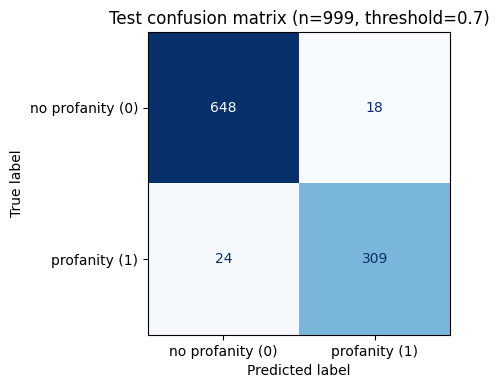

In [ ]:
# Save metrics, predictions (without review text) and the confusion matrix figure
metrics = {
    "n_test": int(len(test)),
    "threshold": TH,
    "precision": float(p),
    "recall": float(r),
    "f1": float(f),
    "confusion_matrix": cm.tolist(),
    "recall_by_profanity_type": {k: float(v) for k, v in recall_by_type.items()},
}
with open(f"{RESULTS_DIR}/test_metrics.json", "w") as fh:
    json.dump(metrics, fh, indent=2)

test[["custom_id", "domain", "profanity_type", "is_profane", "prob", "pred"]].to_csv(
    f"{RESULTS_DIR}/test_predictions.csv", index=False)

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=["no profanity (0)", "profanity (1)"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title(f"Test confusion matrix (n={len(test)}, threshold={TH})")
fig.tight_layout()
fig.savefig(f"{RESULTS_DIR}/confusion_matrix.png", dpi=150)
plt.show()

## 6. Error analysis

The most confident mistakes on the test set. The written discussion of the mistakes, their likely causes and suggested improvements is in the README.

In [ ]:
pd.set_option("display.max_colwidth", 200)

test_fp = test[(test.pred == 1) & (test.is_profane == 0)].sort_values("prob", ascending=False)
test_fn = test[(test.pred == 0) & (test.is_profane == 1)].sort_values("prob")
test_fp[["text", "prob"]].head(12)

,text,prob
692,Котің кысшы,0.991047
610,Базар жох ютуб тын бастықтары админстатрлары ақшаны қырып тауып атр ғо,0.989874
490,Мен қалай тіркелетін бл мим,0.988204
732,Секско нау кыздар сыгысесндерма жанеля калай карайсын сен маган унайсын жанм сол ай ловеюго журек деген сен ушн урп тур сгсейкш,0.978580
886,ана ай лав ю деп жазған менғо😅😅,0.977659
721,МААА МАГАН УНАГАН ЖОК ОШИП КОСЫЛЫП БОЛГАН УНАМАДЫ ШЫГАРШАН АДАМ КАНДАЙ АДАМ ТУПОЙ МА? ОЙ МБ КУРТЫП DARYN. ONLINE ОГАН КОСА ОБЛ ДИД СОСЫН 2 АПТА АЙНАЛАДЫ ОУФ СОНДАЙ ЕНДИ СЕНДЕРДЕ ШЕ? МАГАН УНАМАДЫ ...,0.949496
984,"вка кушты сендер айқай Сізбен, АТА-АНАСЫНЫН УМЫТЫН АКТАСЫН ДЕП ТЫЛЕЙМ.САУ БОЛЫНДАР ДОСТАР мен сызды жаксы корем ана мен сызды қаты қаты сыз сйак ты болгм келет сыз тағам дар жасай сз тағ көп таға ...",0.945257
616,Өте керемет тик ток қа осы арқылы видио салуға болады 💙💙и падпишігім көбиді,0.944025
442,Кетше сен,0.936414
376,достар осылай ұқсас керемет игра жазып алыңыздар аты MadOuit2 мен ойнап келе жатқанда 8ай дай болп калды 68дей машина бар барлык машина бар іздеген машина камаз бүкіл әлем көліктер сода апкилер кй...,0.920825


In [ ]:
test_fn[["text", "prob", "profanity_type"]].head(12)

,text,prob,profanity_type
284,"Блять 5 минутым кетті, платный екенін қайдан білейін",0.003218,russian
101,Әлхамдулиллях!өте тамаша!машаллах!үйренуге ыңғайлы.,0.004141,russian
1,"Көзімнен жасты ыршытып шығарған кітап болды бұл. Қиын қыстау кездердегі сатқындық, жүрекке пышақ сұққанмен бірдей ақ екен.",0.004385,russian
282,Ебат қиыне,0.006509,russian
54,Өтініш кіредитім 3ай мерзімге тоқтата тұрғанымызды өтінемін өтініш иесі далбаев құлман сұлтанұлы,0.006808,russian
303,👍👍👍👍пиздес күшті,0.009818,russian
295,Кірмеіт сука,0.010306,russian
237,Сіккен оиын брак достарынмен оинаи аламыз,0.017552,kazakh
185,Бла кушты ойн,0.020022,kazakh
152,амымды жалаған сияқты🍑🍌күшті,0.025286,kazakh


## 7. Publish the model to the Hugging Face Hub

Needs a Hugging Face token with **write** access stored in Colab Secrets as `HF_WRITE_TOKEN`. Set `REPO_ID` to your own `username/model-name` and `PUSH_TO_HUB = True`.

In [ ]:
PUSH_TO_HUB = False
REPO_ID = "karlygaw/kazakh-profanity-xlmr"

if PUSH_TO_HUB:
    from google.colab import userdata
    from huggingface_hub import HfApi, login

    login(token=userdata.get("HF_WRITE_TOKEN"))
    best_model.push_to_hub(REPO_ID)
    tokenizer.push_to_hub(REPO_ID)
    HfApi().upload_file(path_or_fileobj=f"{MODEL_DIR}/inference_config.json",
                        path_in_repo="inference_config.json", repo_id=REPO_ID)
    print(f"https://huggingface.co/{REPO_ID}")

## Environment

In [ ]:
from importlib.metadata import version, PackageNotFoundError

for pkg in ["torch", "transformers", "scikit-learn", "pandas", "numpy", "matplotlib"]:
    try:
        print(f"{pkg}=={version(pkg)}")
    except PackageNotFoundError:
        pass

torch==2.14.1+cu130
transformers==5.22.1
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6
matplotlib==3.10.0


In [ ]:
import numpy as np
import pandas as pd
import torch
from google.colab import drive
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from transformers import AutoModelForSequenceClassification, AutoTokenizer

drive.mount("/content/drive")
REPO_ID = "karlygaw/kazakh-profanity-xlmr"

test = pd.read_csv("/content/drive/MyDrive/kazakh_profanity_data/test.csv")
tok = AutoTokenizer.from_pretrained(REPO_ID)
model = AutoModelForSequenceClassification.from_pretrained(REPO_ID).eval()

probs = []
with torch.no_grad():
    for i in range(0, len(test), 64):
        enc = tok(test["text"].iloc[i:i + 64].tolist(), truncation=True,
                  max_length=128, padding=True, return_tensors="pt")
        probs.append(torch.softmax(model(**enc).logits, -1)[:, 1].numpy())
pred = (np.concatenate(probs) >= 0.70).astype(int)

print(precision_recall_fscore_support(test["is_profane"], pred, average="binary")[:3])
print(confusion_matrix(test["is_profane"], pred))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


config.json:   0%|          | 0.00/811 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/533 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

(0.944954128440367, 0.9279279279279279, 0.9363636363636364)
[[648  18]
 [ 24 309]]
